## Unsupervised clustering - "these features in their log form"

Models: **K-Means, Gaussian Mixture, Hierarchical (Ward), DBSCAN, HDBSCAN** over the
11-feature set (LIFECYCLE/ENGAGEMENT/ECONOMIC/OPTIONAL) transformed into its log form
where skew > 3 (see "Requested 11-feature matrix" section). Complete-case rows only
(depositors), standardised (z-score). Constant columns dropped automatically
(e.g. `has_deposited` is all-True in the depositor subset).

Metric interpretation = *geometric separation*:
- **Silhouette** [-1, 1], higher = well separated, compact (0.70+ strong, 0.50-0.70 moderate, < 0.25 weak)
- **Davies-Bouldin** [0, inf), lower = better (low avg of intra/inter distance ratios)
- **Calinski-Harabasz** [0, inf), higher = better (between / within scatter ratio)

Hierarchical runs on a 6,000-player random subsample (Ward is O(n^2) memory at 60k).
All outputs: `models/csv/*.csv`, `models/viz/*.png`.

In [1]:
import os, numpy as np, pandas as pd, matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (silhouette_score, silhouette_samples,
                             davies_bouldin_score, calinski_harabasz_score)
from scipy.cluster.hierarchy import linkage, dendrogram
import hdbscan
from mpl_toolkits.mplot3d import Axes3D
from matplotlib import animation as _anim_mod

OUT = "models"; CSV = f"{OUT}/csv"; VIZ = f"{OUT}/viz"


def _find_up(name, start=None):
    d = os.path.abspath(start or os.getcwd())
    while True:
        if os.path.exists(os.path.join(d, name)):
            return d
        p = os.path.dirname(d)
        if p == d:
            raise FileNotFoundError(name)
        d = p


PROJECT = _find_up("Data Science Task Data.xlsx - Result 1.csv")
OUT = f"{PROJECT}/models"; CSV = f"{OUT}/csv"; VIZ = f"{OUT}/viz"
for d_ in (OUT, CSV, VIZ):
    os.makedirs(d_, exist_ok=True)
SAMPLE, RS, SS = 5000, 42, 6000
plt.rcParams["figure.dpi"] = 110
print("env ok | project:", PROJECT)

env ok | project: /mnt/c/Users/ktsar/OneDrive/Documents/Betty_v1


### 1) Feature matrix (log forms, complete case)

In [2]:
SRC = f"{PROJECT}/Data Science Task Data.xlsx - Result 1.csv"
FEATS = f"{PROJECT}/features/player_features.csv"

raw = pd.read_csv(SRC, low_memory=False, parse_dates=["first_deposit_day"],
                  usecols=["player_id", "first_deposit_day"])
pf1 = pd.read_csv(FEATS, low_memory=False, usecols=[
    "player_id", "tenure_days", "time_to_first_deposit", "total_logins",
    "login_rate", "total_deposits", "total_withdrawals", "withdrawal_ratio",
    "bets_per_login", "net_deposits", "bets_to_deposit_ratio"])
pf1 = pf1.merge(raw, on="player_id", how="left")
pf1["has_deposited"] = pf1["first_deposit_day"].notna()
pf1 = pf1.rename(columns={"bets_to_deposit_ratio": "turnover_to_deposit_ratio"})

def _slog1p(x):
    return np.sign(x) * np.log1p(np.abs(x))

FORMS = {
    "tenure_days": (None, "raw"),
    "time_to_first_deposit": (lambda s: _slog1p(s), "slog1p"),
    "has_deposited": (None, "raw flag"),
    "total_logins": (lambda s: np.log1p(s), "log1p"),
    "login_rate": (lambda s: np.log1p(s), "log1p"),
    "total_deposits": (lambda s: np.log1p(s), "log1p"),
    "total_withdrawals": (lambda s: np.log1p(s), "log1p"),
    "turnover_to_deposit_ratio": (lambda s: np.log1p(s), "log1p"),
    "withdrawal_ratio": (lambda s: np.log1p(s), "log1p"),
    "bets_per_login": (lambda s: np.log1p(s), "log1p"),
    "net_deposits": (lambda s: _slog1p(s), "slog1p"),
}
mat = pd.DataFrame({"player_id": pf1["player_id"]})
for c, (f, name) in FORMS.items():
    mat[f"{name.split()[-1]}_{c}" if f else c] = pf1[c] if f is None else f(pf1[c])
mat = mat.dropna().reset_index(drop=True)
mat.to_csv(f"{CSV}/feature_matrix_11_complete.csv", index=False)

cols = [c for c in mat.columns if c != "player_id"]
const = [c for c in cols if mat[c].nunique() <= 1]
for c in const:
    print(f"dropped constant feature in complete-case subset: {c}")
cols = [c for c in cols if c not in const]

X = StandardScaler().fit_transform(mat[cols])
X = X.astype(np.float64)
np.random.seed(RS)
print(f"complete-case players: {len(mat)} | features after scaling: {len(cols)}")
print("feature set:", ", ".join(cols))
PCA2 = PCA(n_components=2, random_state=RS).fit_transform(X)
PCA3 = PCA(n_components=3, random_state=RS).fit_transform(X)
evr2 = PCA(2, random_state=RS).fit(X).explained_variance_ratio_.sum()
evr3 = PCA(3, random_state=RS).fit(X).explained_variance_ratio_.sum()
print("PCA 2D explained variance: %.1f%% | PCA 3D: %.1f%%" % (evr2 * 100, evr3 * 100))


def cluster_metrics(labels, Xi=X):
    labels = np.asarray(labels)
    nc = len(set(labels) - {-1}); nn = int((labels == -1).sum())
    out = {"n_clusters": nc, "n_noise": nn}
    if nc >= 2:
        try: out["silhouette"] = silhouette_score(Xi, labels, sample_size=SAMPLE, random_state=RS)
        except Exception: out["silhouette"] = np.nan
        core = labels != -1
        if nn:
            try: out["silhouette_core"] = silhouette_score(Xi[core], labels[core], sample_size=SAMPLE, random_state=RS)
            except Exception: out["silhouette_core"] = np.nan
        try: out["davies_bouldin"] = davies_bouldin_score(Xi, labels)
        except Exception: out["davies_bouldin"] = np.nan
        try: out["calinski_harabasz"] = calinski_harabasz_score(Xi, labels)
        except Exception: out["calinski_harabasz"] = np.nan
    else:
        out.update({"silhouette": np.nan, "davies_bouldin": np.nan, "calinski_harabasz": np.nan})
    return out


def cluster_color_map(labels):
    pal = []
    for cm in ["tab20", "tab20b", "tab20c"]:
        pal += [plt.get_cmap(cm)(k) for k in range(20)]
    uniq = [u for u in sorted(set(labels)) if u != -1]
    return {u: pal[i % len(pal)] for i, u in enumerate(uniq)}


def pca_scatter(labels, title, fname, X2=None):
    X2 = PCA2 if X2 is None else X2
    labels = np.asarray(labels).astype(int)
    uniq = [u for u in np.unique(labels)]
    cmap_ = cluster_color_map(labels)
    fig, ax = plt.subplots(figsize=(9, 7))
    for u in uniq:
        m = labels == u
        c = "0.62" if u == -1 else cmap_[u]
        label = "noise" if u == -1 else f"cluster {u}"
        ax.scatter(X2[m, 0], X2[m, 1], s=8, alpha=0.75, c=c, label=label)
    ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.set_title(title)
    ax.legend(markerscale=4, fontsize=8, loc="best")
    plt.savefig(f"{VIZ}/{fname}", dpi=120, bbox_inches="tight")
    plt.show(); plt.close(fig)


def pca_scatter_3d(labels, title, fname, X3=None, n_frames=96, fps=12):
    X3 = PCA3 if X3 is None else X3
    labels = np.asarray(labels).astype(int)
    uniq = [u for u in np.unique(labels)]
    cmap_ = cluster_color_map(labels)
    fig = plt.figure(figsize=(10, 8))
    ax = fig.add_subplot(111, projection="3d")
    for u in uniq:
        m = labels == u
        c = "0.62" if u == -1 else cmap_.get(u, "0.5")
        lab = "noise" if u == -1 else f"cluster {u}"
        ax.scatter(X3[m, 0], X3[m, 1], X3[m, 2], s=4, alpha=0.65, c=c, label=lab)
    ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.set_zlabel("PC3")
    ax.set_title(title)
    ax.legend(markerscale=4, fontsize=8, loc="upper left")
    ax.view_init(elev=20, azim=0)
    anim = _anim_mod.FuncAnimation(fig, lambda f: ax.view_init(20, 360 * f / n_frames),
                                   frames=n_frames, interval=40, blit=False)
    anim.save(f"{VIZ}/{fname}", writer="pillow", fps=fps)
    prev = fname.replace(".gif", "_preview.png")
    ax.view_init(elev=20, azim=0)
    plt.savefig(f"{VIZ}/{prev}", dpi=120, bbox_inches="tight")
    plt.close(fig)
    print(f"[saved] {VIZ}/{fname}, {VIZ}/{prev}")


def profile_heatmap(labels, title, fname, cols_=None, X_=None):
    cols_ = cols if cols_ is None else cols_
    X_ = X if X_ is None else X_
    Z = pd.DataFrame(np.column_stack([labels, X_]), columns=["label"] + cols_)
    prof = Z.groupby("label").mean()
    cmap_ = cluster_color_map(np.asarray(labels).astype(int))
    rc = prof.index.map(lambda c: cmap_.get(int(c), "0.7"))
    g = sns.clustermap(prof, cmap="vlag", center=0, figsize=(11, 6),
                       col_cluster=True, row_cluster=True,
                       row_colors=pd.Series(rc.values, index=prof.index, name="cluster"))
    g.ax_heatmap.set_yticklabels(g.ax_heatmap.get_yticklabels(), rotation=0, fontsize=8)
    g.ax_heatmap.set_xticklabels(g.ax_heatmap.get_xticklabels(), rotation=45, fontsize=8)
    g.fig.suptitle(title, y=1.02)
    g.savefig(f"{VIZ}/{fname}", dpi=120, bbox_inches="tight")
    print(f"[saved] {VIZ}/{fname}")
    plt.close(g.fig)

dropped constant feature in complete-case subset: has_deposited
complete-case players: 59922 | features after scaling: 10
feature set: tenure_days, slog1p_time_to_first_deposit, log1p_total_logins, log1p_login_rate, log1p_total_deposits, log1p_total_withdrawals, log1p_turnover_to_deposit_ratio, log1p_withdrawal_ratio, log1p_bets_per_login, slog1p_net_deposits
PCA 2D explained variance: 58.5% | PCA 3D: 70.2%


### 2) K-Means (k = 2..10 evaluated; final model fixed at k = 6 by request)

Note: metric-optimal k = 2 (silhouette 0.267); k = 6 gives silhouette 0.234, Davies-Bouldin 1.428, Calinski-Harabasz 15,410.

,k,inertia,n_clusters,n_noise,silhouette,davies_bouldin,calinski_harabasz
0,2,435007.232,2,0,0.267,1.486,22619.521
1,3,348839.030,3,0,0.266,1.374,21503.598
2,4,313365.888,4,0,0.250,1.448,18219.209
3,5,282231.984,5,0,0.263,1.346,16823.926
4,6,262129.388,6,0,0.234,1.428,15410.059
5,7,246387.027,7,0,0.224,1.423,14300.020
6,8,233003.957,8,0,0.206,1.473,13452.566
7,9,221811.312,9,0,0.202,1.446,12742.653
8,10,210271.692,10,0,0.205,1.479,12313.539


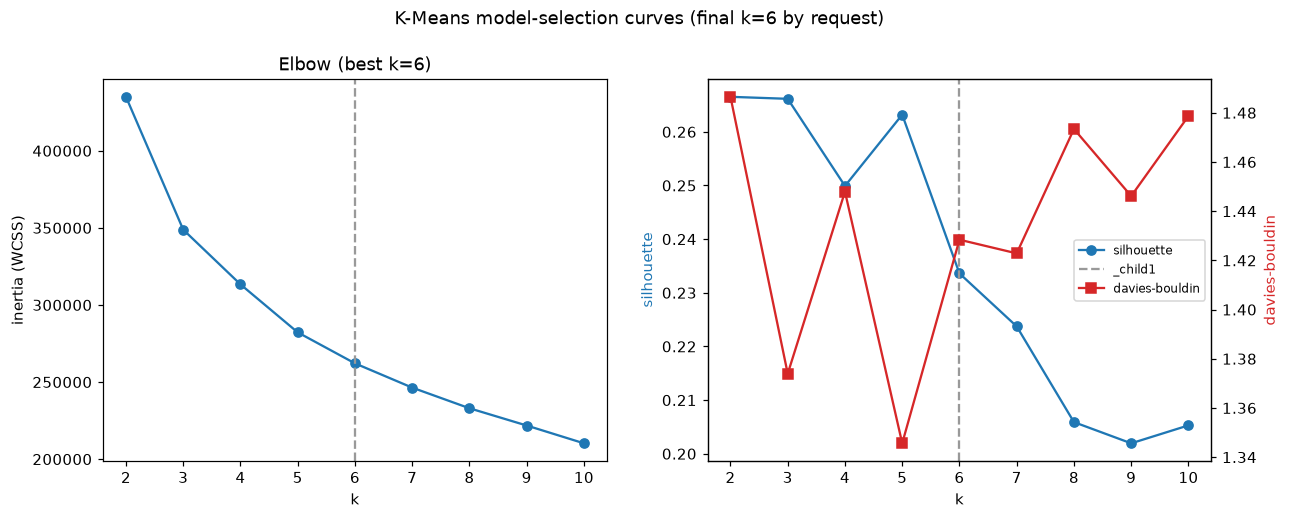

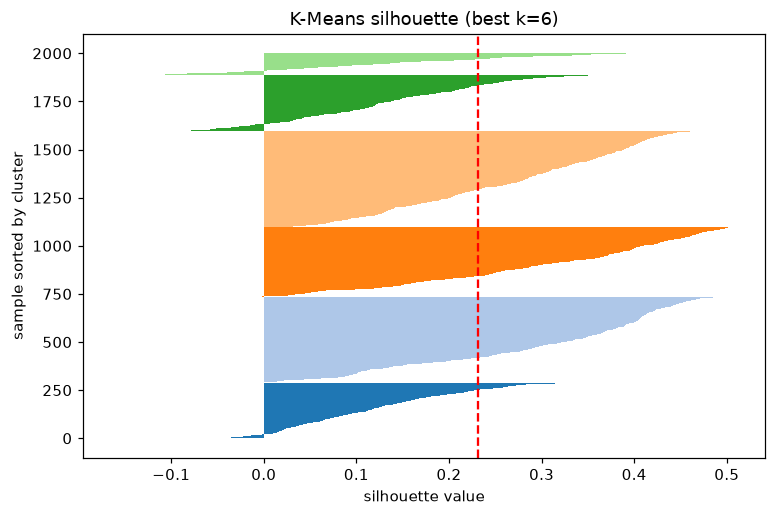

/tmp/ipykernel_208874/1596613672.py:92: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  ax.scatter(X2[m, 0], X2[m, 1], s=8, alpha=0.75, c=c, label=label)


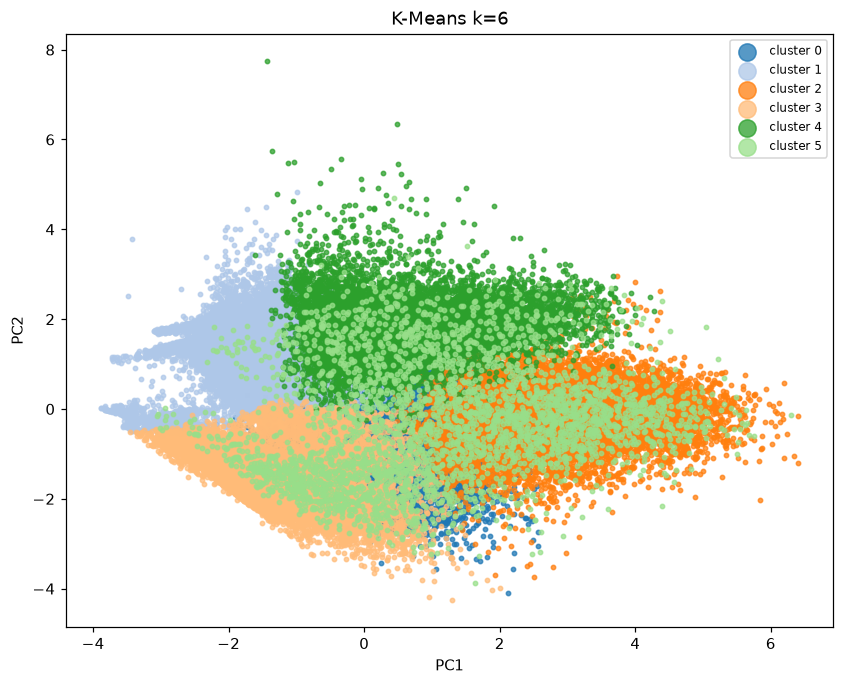

/tmp/ipykernel_208874/1596613672.py:110: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  ax.scatter(X3[m, 0], X3[m, 1], X3[m, 2], s=4, alpha=0.65, c=c, label=lab)


[saved] /mnt/c/Users/ktsar/OneDrive/Documents/Betty_v1/models/viz/kmeans_3d.gif, /mnt/c/Users/ktsar/OneDrive/Documents/Betty_v1/models/viz/kmeans_3d_preview.png


[saved] /mnt/c/Users/ktsar/OneDrive/Documents/Betty_v1/models/viz/kmeans_profiles.png


[best k] 6  metrics: {'n_clusters': 6, 'n_noise': 0, 'silhouette': 0.23360968345383026, 'davies_bouldin': 1.4284038657827585, 'calinski_harabasz': 15410.059020366285}


In [3]:
rows = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=RS).fit(X)
    rows.append({"k": k, "inertia": km.inertia_, **cluster_metrics(km.labels_, X)})
kdf = pd.DataFrame(rows)[["k", "inertia", "n_clusters", "n_noise", "silhouette", "davies_bouldin", "calinski_harabasz"]]
kdf.to_csv(f"{CSV}/kmeans_metrics.csv", index=False)
display(kdf.round(3))

# fixed by request: final K-Means model at k = 6 (not silhouette argmax)
best_k = 6
km = KMeans(n_clusters=best_k, n_init=10, random_state=RS).fit(X)
lbl = km.labels_

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(kdf["k"], kdf["inertia"], "o-"); axes[0].axvline(best_k, ls="--", c="0.6")
axes[0].set(xlabel="k", ylabel="inertia (WCSS)", title=f"Elbow (best k={best_k})")
ax2 = axes[1].twinx()
axes[1].plot(kdf["k"], kdf["silhouette"], "o-", c="C0", label="silhouette"); axes[1].set_xlabel("k")
ax2.plot(kdf["k"], kdf["davies_bouldin"], "s-", c="C3", label="davies-bouldin")
axes[1].set_ylabel("silhouette", color="C0"); ax2.set_ylabel("davies-bouldin", color="C3")
axes[1].axvline(best_k, ls="--", c="0.6"); lines = axes[1].get_lines() + ax2.get_lines()
axes[1].legend(lines, [l.get_label() for l in lines], loc="center right", fontsize=8)
fig.suptitle(f"K-Means model-selection curves (final k={best_k} by request)", y=1.02)
plt.savefig(f"{VIZ}/kmeans_elbow.png", dpi=120, bbox_inches="tight")
plt.show(); plt.close(fig)

sub = np.random.default_rng(RS).choice(len(X), 2000, replace=False)
slh = silhouette_samples(X[sub], lbl[sub])
fig, ax = plt.subplots(figsize=(8, 5))
cmap_ = cluster_color_map(lbl[sub])
lo = 0
for cl in range(best_k):
    seg = slh[lbl[sub] == cl]
    seg.sort()
    ax.barh(range(lo, lo + len(seg)), seg, height=1, edgecolor="none",
            color=cmap_.get(cl, "0.5"))
    lo += len(seg)
ax.axvline(slh.mean(), c="r", ls="--"); ax.set(title=f"K-Means silhouette (best k={best_k})",
    xlabel="silhouette value", ylabel="sample sorted by cluster")
plt.savefig(f"{VIZ}/kmeans_silhouette.png", dpi=120, bbox_inches="tight")
plt.show(); plt.close(fig)

pd.DataFrame({"player_id": mat["player_id"], "cluster": lbl}).to_csv(f"{CSV}/kmeans_assignments.csv", index=False)
pd.DataFrame(km.cluster_centers_, columns=cols).to_csv(f"{CSV}/kmeans_centers.csv", index=False)
pca_scatter(lbl, f"K-Means k={best_k}", "kmeans_pca_scatter.png")
pca_scatter_3d(lbl, f"K-Means k={best_k} - 3D PCA", "kmeans_3d.gif")
profile_heatmap(lbl, f"K-Means k={best_k} - mean z-score profile", "kmeans_profiles.png")
print(f"[best k] {best_k}  metrics: {cluster_metrics(lbl)}")

### 3) Gaussian Mixture Model (k = 2..10)

,k,bic,aic,n_clusters,n_noise,silhouette,davies_bouldin,calinski_harabasz
0,2,814266.44,813087.34,2,0,0.18,1.92,14607.05
1,3,7340.34,5567.18,3,0,0.24,1.46,17112.26
2,4,-145816.42,-148183.63,4,0,0.19,3.10,10256.92
3,5,-250551.06,-253512.33,5,0,0.12,3.88,8616.64
4,6,-342070.25,-345625.57,6,0,0.11,3.33,8051.43
5,7,-387328.99,-391478.36,7,0,0.10,3.43,7198.69
6,8,-462448.19,-467191.61,8,0,0.09,3.55,6093.20
7,9,-489834.34,-495171.81,9,0,0.08,3.47,5755.19
8,10,-569317.49,-575249.01,10,0,0.07,3.34,5863.88


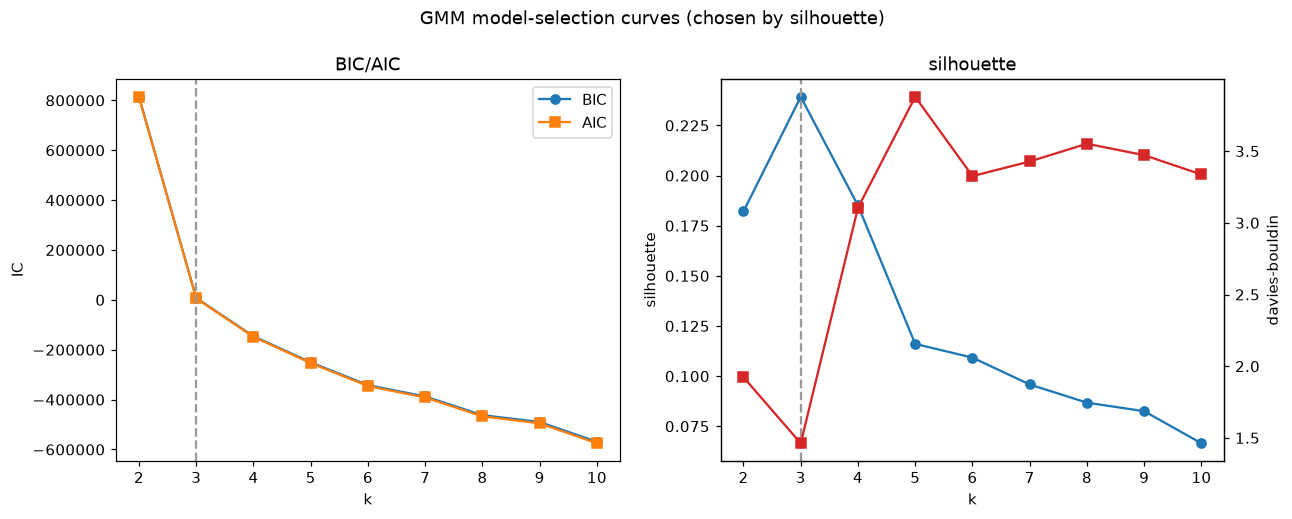

/tmp/ipykernel_208874/1596613672.py:92: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  ax.scatter(X2[m, 0], X2[m, 1], s=8, alpha=0.75, c=c, label=label)


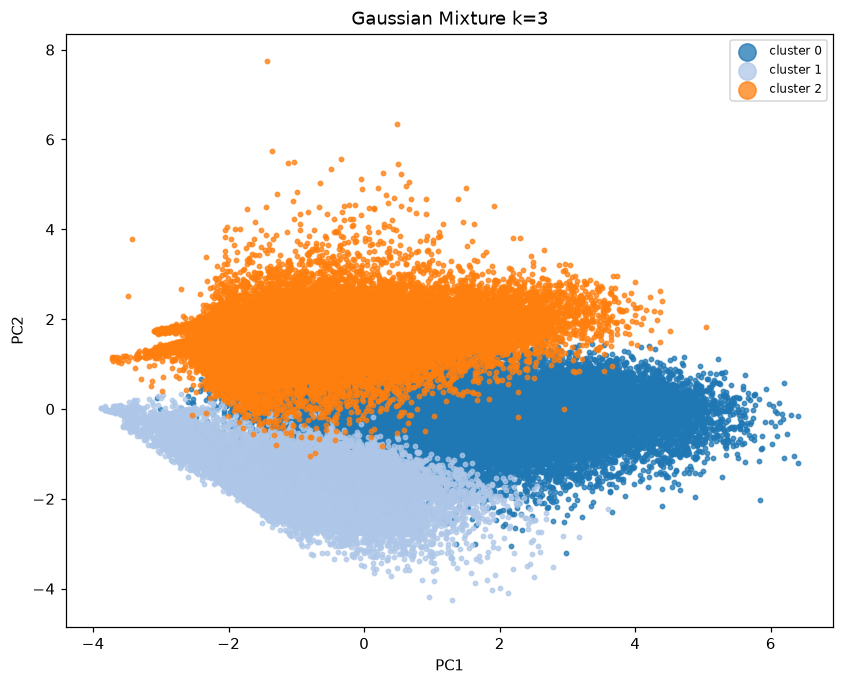

/tmp/ipykernel_208874/1596613672.py:110: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  ax.scatter(X3[m, 0], X3[m, 1], X3[m, 2], s=4, alpha=0.65, c=c, label=lab)


[saved] /mnt/c/Users/ktsar/OneDrive/Documents/Betty_v1/models/viz/gmm_3d.gif, /mnt/c/Users/ktsar/OneDrive/Documents/Betty_v1/models/viz/gmm_3d_preview.png


[saved] /mnt/c/Users/ktsar/OneDrive/Documents/Betty_v1/models/viz/gmm_profiles.png


[best k] 3  metrics: {'n_clusters': 3, 'n_noise': 0, 'silhouette': 0.23926104599565773, 'davies_bouldin': 1.4621142935825286, 'calinski_harabasz': 17112.261470964753}


In [4]:
grows = []
for k in range(2, 11):
    gm = GaussianMixture(n_components=k, covariance_type="full", max_iter=300, random_state=RS).fit(X)
    lab = gm.predict(X)
    grows.append({"k": k, "bic": gm.bic(X), "aic": gm.aic(X), **cluster_metrics(lab, X)})
gdf = pd.DataFrame(grows)[["k", "bic", "aic", "n_clusters", "n_noise", "silhouette", "davies_bouldin", "calinski_harabasz"]]
gdf.to_csv(f"{CSV}/gmm_metrics.csv", index=False)
display(gdf.round(2))

bk = int(gdf.loc[gdf["silhouette"].idxmax(), "k"])
gm = GaussianMixture(n_components=bk, covariance_type="full", max_iter=300, random_state=RS).fit(X)
lbl = gm.predict(X)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(gdf["k"], gdf["bic"], "o-", label="BIC"); axes[0].plot(gdf["k"], gdf["aic"], "s-", label="AIC")
axes[0].axvline(bk, ls="--", c="0.6"); axes[0].set(xlabel="k", ylabel="IC", title="BIC/AIC")
axes[0].legend()
ax2 = axes[1].twinx()
axes[1].plot(gdf["k"], gdf["silhouette"], "o-", c="C0"); axes[1].set(xlabel="k", ylabel="silhouette", title="silhouette")
ax2.plot(gdf["k"], gdf["davies_bouldin"], "s-", c="C3"); ax2.set(ylabel="davies-bouldin")
axes[1].axvline(bk, ls="--", c="0.6")
fig.suptitle("GMM model-selection curves (chosen by silhouette)", y=1.02)
plt.savefig(f"{VIZ}/gmm_aic_bic.png", dpi=120, bbox_inches="tight")
plt.show(); plt.close(fig)

pd.DataFrame({"player_id": mat["player_id"], "cluster": lbl}).to_csv(f"{CSV}/gmm_assignments.csv", index=False)
pca_scatter(lbl, f"Gaussian Mixture k={bk}", "gmm_pca_scatter.png")
pca_scatter_3d(lbl, f"Gaussian Mixture k={bk} - 3D PCA", "gmm_3d.gif")
profile_heatmap(lbl, f"GMM k={bk} - mean z-score profile", "gmm_profiles.png")
print(f"[best k] {bk}  metrics: {cluster_metrics(lbl)}")

### 4) Hierarchical clustering (Ward, subsampled)

,k,n_clusters,n_noise,silhouette,davies_bouldin,calinski_harabasz
0,2,2,0,0.221,1.737,1772.542
1,3,3,0,0.211,1.423,1654.141
2,4,4,0,0.228,1.513,1492.834
3,5,5,0,0.217,1.439,1368.085
4,6,6,0,0.186,1.489,1261.550
5,7,7,0,0.171,1.514,1183.294
6,8,8,0,0.162,1.542,1105.037
7,9,9,0,0.167,1.554,1041.557
8,10,10,0,0.163,1.634,986.542


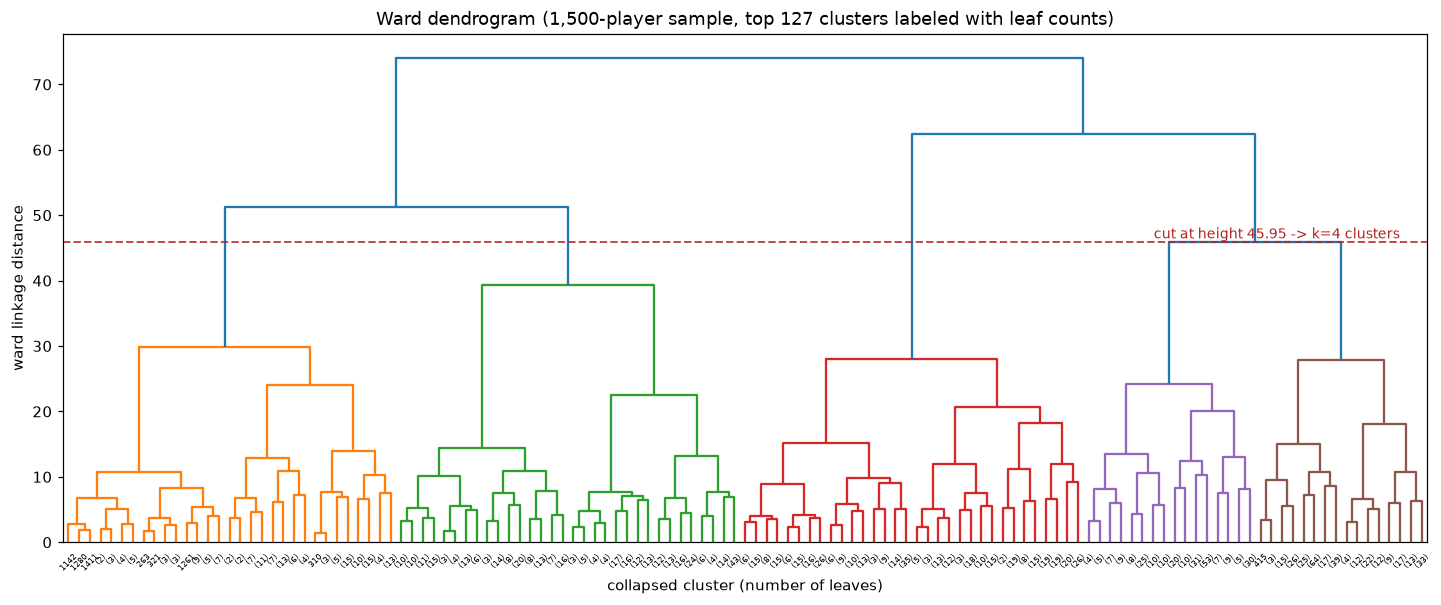

/tmp/ipykernel_208874/1596613672.py:92: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  ax.scatter(X2[m, 0], X2[m, 1], s=8, alpha=0.75, c=c, label=label)


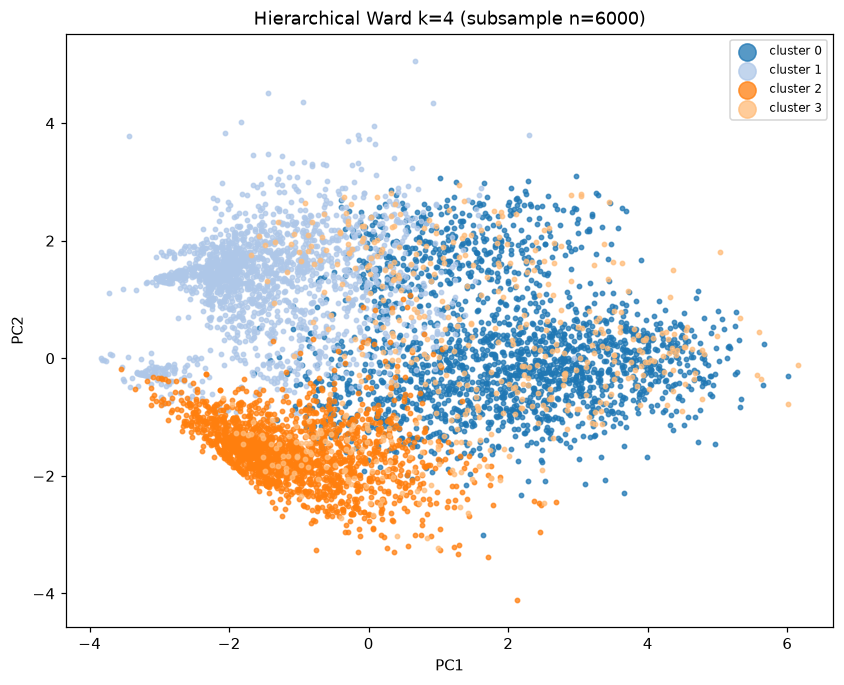

/tmp/ipykernel_208874/1596613672.py:110: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  ax.scatter(X3[m, 0], X3[m, 1], X3[m, 2], s=4, alpha=0.65, c=c, label=lab)


[saved] /mnt/c/Users/ktsar/OneDrive/Documents/Betty_v1/models/viz/hier_3d.gif, /mnt/c/Users/ktsar/OneDrive/Documents/Betty_v1/models/viz/hier_3d_preview.png


[saved] /mnt/c/Users/ktsar/OneDrive/Documents/Betty_v1/models/viz/hier_profiles.png


[best k] 4  metrics (subsample): {'n_clusters': 4, 'n_noise': 0, 'silhouette': 0.22780678117238295, 'davies_bouldin': 1.512660672185369, 'calinski_harabasz': 1492.833673220093}
(hierarchical run on subsample of n=6000; dendrogram on n=1500)


In [5]:
rng = np.random.default_rng(RS)
idx = rng.choice(len(X), SS, replace=False)
Xs = X[idx]; pids = mat["player_id"].iloc[idx].to_numpy()
hrows = []
for k in range(2, 11):
    hc = AgglomerativeClustering(n_clusters=k, linkage="ward").fit(Xs)
    hrows.append({"k": k, **cluster_metrics(hc.labels_, Xs)})
hidf = pd.DataFrame(hrows)[["k", "n_clusters", "n_noise", "silhouette", "davies_bouldin", "calinski_harabasz"]]
hidf.to_csv(f"{CSV}/hier_metrics.csv", index=False)
display(hidf.round(3))

bk = int(hidf.loc[hidf["silhouette"].idxmax(), "k"])
hc = AgglomerativeClustering(n_clusters=bk, linkage="ward").fit(Xs)
lbl = hc.labels_

sub2 = idx[rng.choice(len(Xs), 1500, replace=False)]
Z = linkage(X[sub2], method="ward")
n_leaves = len(Z) + 1
cut = float(Z[n_leaves - bk - 1, 2]) if bk < n_leaves else float(Z[-1, 2])
fig, ax = plt.subplots(figsize=(16, 6))
dend = dendrogram(Z, truncate_mode="level", p=6, no_labels=False,
                  color_threshold=cut, leaf_rotation=45, ax=ax)
ax.axhline(cut, color="firebrick", ls="--", lw=1.3, alpha=0.8)
ax.annotate(f"cut at height {cut:.2f} -> k={bk} clusters", xy=(0.98, cut),
            xycoords=("axes fraction", "data"), color="firebrick",
            va="bottom", ha="right", fontsize=9)
tick_labs = [t.get_text() for t in ax.get_xticklabels()]
ax.set(title=f"Ward dendrogram (1,500-player sample, top {len(tick_labs)} clusters labeled with leaf counts)",
       xlabel="collapsed cluster (number of leaves)", ylabel="ward linkage distance")
plt.savefig(f"{VIZ}/hier_dendrogram.png", dpi=120, bbox_inches="tight")
plt.show(); plt.close(fig)

pd.DataFrame({"player_id": pids, "cluster": lbl}).to_csv(f"{CSV}/hier_assignments.csv", index=False)
pca_scatter(lbl, f"Hierarchical Ward k={bk} (subsample n={SS})", "hier_pca_scatter.png", X2=PCA2[idx])
pca_scatter_3d(lbl, f"Hierarchical k={bk} - 3D PCA", "hier_3d.gif", X3=PCA3[idx])
profile_heatmap(lbl, f"Hierarchical k={bk} - mean z-score profile", "hier_profiles.png", X_=Xs)
print(f"[best k] {bk}  metrics (subsample): {cluster_metrics(lbl, Xs)}")
print(f"(hierarchical run on subsample of n={SS}; dendrogram on n=1500)")

### 5) DBSCAN (density) -- subsample n=15,000

DBSCAN exhausts memory on the full 60k for dense epsighbourhoods (confirmed OOM / kernel kill), so it is run on a deterministic 15,000-player subsample (reported in the summary).

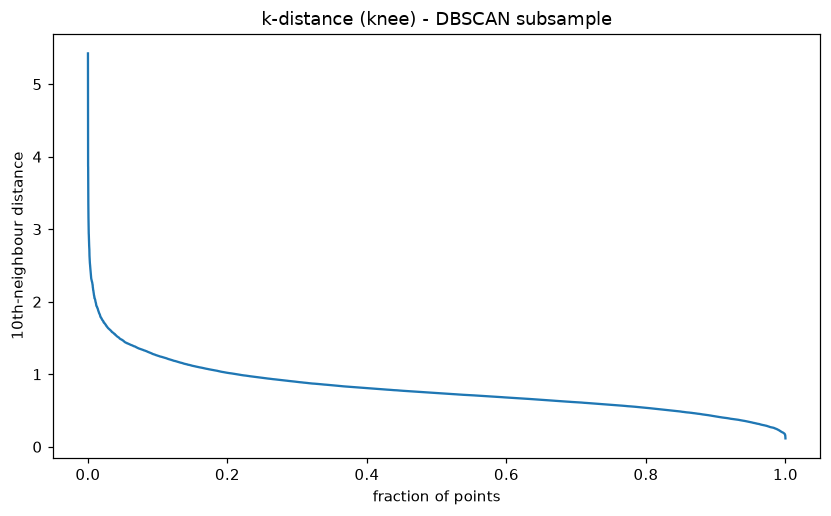

,eps,min_samples,n_clusters,n_noise,silhouette,silhouette_core,davies_bouldin,calinski_harabasz
0,0.75,5,27,3053,-0.362,-0.324,1.475,40.142
1,1.00,5,19,1039,-0.141,-0.115,1.585,38.017
2,1.50,5,2,123,0.291,NaN,2.125,69.733
3,2.00,5,1,28,NaN,NaN,NaN,NaN
4,3.00,5,1,0,NaN,NaN,NaN,NaN
5,0.75,10,6,4288,-0.249,-0.202,2.127,145.547
6,1.00,10,1,1652,NaN,NaN,NaN,NaN
7,1.50,10,1,200,NaN,NaN,NaN,NaN
8,2.00,10,1,41,NaN,NaN,NaN,NaN
9,3.00,10,1,1,NaN,NaN,NaN,NaN


/tmp/ipykernel_208874/2008019847.py:35: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  ax.scatter(PCA2d[m, 0], PCA2d[m, 1], c=cmap_.get(u, "0.5"), s=8, alpha=0.75,


/tmp/ipykernel_208874/1596613672.py:110: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  ax.scatter(X3[m, 0], X3[m, 1], X3[m, 2], s=4, alpha=0.65, c=c, label=lab)


[saved] /mnt/c/Users/ktsar/OneDrive/Documents/Betty_v1/models/viz/dbscan_3d.gif, /mnt/c/Users/ktsar/OneDrive/Documents/Betty_v1/models/viz/dbscan_3d_preview.png


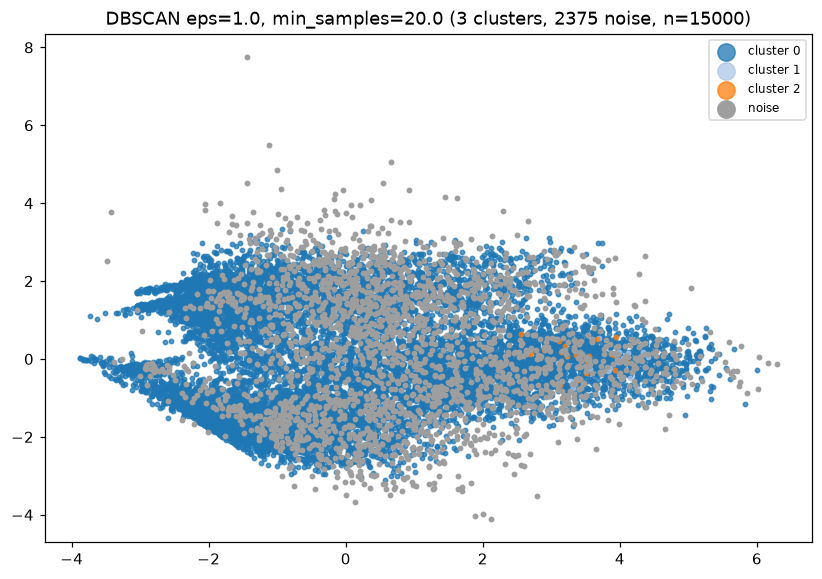

[best config] eps=1.0, min_samples=20.0, n=15000 subsample


metrics (subsample, incl noise): {'n_clusters': 3, 'n_noise': 2375, 'silhouette': 0.13652233852254575, 'silhouette_core': 0.3030375462564545, 'davies_bouldin': 2.1081201282292064, 'calinski_harabasz': 362.2429192158036}


In [6]:
DB_N = 15000
rng2 = np.random.default_rng(RS)
idx2 = rng2.choice(len(X), DB_N, replace=False)
Xd = X[idx2]; PCA2d = PCA2[idx2]; pids_d = mat["player_id"].iloc[idx2].to_numpy()

nbrs = NearestNeighbors(n_neighbors=11).fit(Xd)
kdist = np.sort(nbrs.kneighbors(Xd)[0][:, -1])[::-1]
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(np.arange(1, len(kdist) + 1) / len(kdist), kdist)
ax.set(xlabel="fraction of points", ylabel="10th-neighbour distance", title="k-distance (knee) - DBSCAN subsample")
plt.savefig(f"{VIZ}/dbscan_knee.png", dpi=120, bbox_inches="tight")
plt.show(); plt.close(fig)

drows = []
for ms in [5, 10, 20]:
    for eps in [0.75, 1.0, 1.5, 2.0, 3.0]:
        db = DBSCAN(eps=eps, min_samples=ms).fit(Xd)
        drows.append({"eps": eps, "min_samples": ms, **cluster_metrics(db.labels_, Xd)})
ddf = pd.DataFrame(drows)[["eps", "min_samples", "n_clusters", "n_noise", "silhouette", "silhouette_core", "davies_bouldin", "calinski_harabasz"]]
ddf.to_csv(f"{CSV}/dbscan_metrics.csv", index=False)
display(ddf.round(3))

ddf2 = ddf.assign(sel=ddf["silhouette_core"].fillna(ddf["silhouette"]).fillna(-9))
best = ddf2.loc[ddf2["sel"].idxmax()]
db = DBSCAN(eps=float(best["eps"]), min_samples=int(best["min_samples"])).fit(Xd)
lbl = db.labels_

fig, ax = plt.subplots(figsize=(9, 6))
cmap_ = cluster_color_map(lbl)
nn = lbl == -1
for u in sorted(set(lbl)):
    if u == -1:
        continue
    m = lbl == u
    ax.scatter(PCA2d[m, 0], PCA2d[m, 1], c=cmap_.get(u, "0.5"), s=8, alpha=0.75,
               label=f"cluster {u}")
ax.scatter(PCA2d[nn, 0], PCA2d[nn, 1], c="0.62", s=8, label="noise")
ax.legend(markerscale=4, fontsize=8, loc="best"); ax.set_title(f"DBSCAN eps={best['eps']}, min_samples={best['min_samples']} "
                                       f"({int(best['n_clusters'])} clusters, {int(best['n_noise'])} noise, n={DB_N})")
plt.savefig(f"{VIZ}/dbscan_pca_scatter.png", dpi=120, bbox_inches="tight")

pca_scatter_3d(lbl, f"DBSCAN eps={best['eps']} min_samples={best['min_samples']} - 3D PCA", "dbscan_3d.gif", X3=PCA3[idx2])
plt.show(); plt.close(fig)

pd.DataFrame({"player_id": pids_d, "cluster": lbl}).to_csv(f"{CSV}/dbscan_assignments.csv", index=False)
print(f"[best config] eps={best['eps']}, min_samples={best['min_samples']}, n={DB_N} subsample")
print(f"metrics (subsample, incl noise): {cluster_metrics(lbl, Xd)}")

### 6) HDBSCAN (hierarchical density clustering)

,min_cluster_size,min_samples,n_clusters,n_noise,silhouette,silhouette_core,davies_bouldin,calinski_harabasz
0,100,1,30,30794,-0.230,-0.001,2.547,962.077
1,100,5,18,33386,-0.242,-0.041,2.745,1349.776
2,250,1,9,17192,-0.183,-0.138,3.146,2136.257
3,250,5,10,33633,-0.173,0.002,3.683,2341.344
4,500,1,6,18274,-0.149,-0.107,4.022,2818.956
5,500,5,7,31438,-0.142,0.020,4.062,3486.741


/tmp/ipykernel_208874/1596613672.py:92: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  ax.scatter(X2[m, 0], X2[m, 1], s=8, alpha=0.75, c=c, label=label)


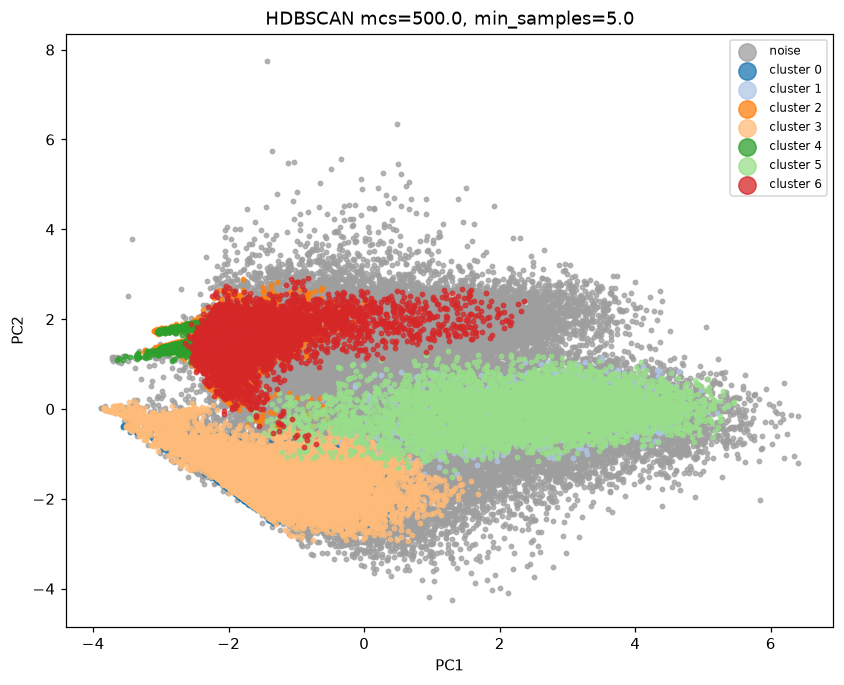

/tmp/ipykernel_208874/1596613672.py:110: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  ax.scatter(X3[m, 0], X3[m, 1], X3[m, 2], s=4, alpha=0.65, c=c, label=lab)


[saved] /mnt/c/Users/ktsar/OneDrive/Documents/Betty_v1/models/viz/hdbscan_3d.gif, /mnt/c/Users/ktsar/OneDrive/Documents/Betty_v1/models/viz/hdbscan_3d_preview.png
[best config] min_cluster_size=500.0, min_samples=5.0


all-points: {'n_clusters': 7, 'n_noise': 31438, 'silhouette': -0.14249582595190907, 'silhouette_core': 0.020372101674076496, 'davies_bouldin': 4.061548403499824, 'calinski_harabasz': 3486.7410893743677}


In [7]:
hrows = []
for mcs in [100, 250, 500]:
    for ms in [1, 5]:
        hd = hdbscan.HDBSCAN(min_cluster_size=mcs, min_samples=ms, core_dist_n_jobs=-1).fit(X)
        hrows.append({"min_cluster_size": mcs, "min_samples": ms, **cluster_metrics(hd.labels_)})
hdf = pd.DataFrame(hrows)[["min_cluster_size", "min_samples", "n_clusters", "n_noise",
                           "silhouette", "silhouette_core", "davies_bouldin", "calinski_harabasz"]]
hdf.to_csv(f"{CSV}/hdbscan_metrics.csv", index=False)
display(hdf.round(3))

hbest = hdf.assign(sel=hdf["silhouette_core"].fillna(-9)).sort_values("sel", ascending=False).iloc[0]
hd = hdbscan.HDBSCAN(min_cluster_size=int(hbest["min_cluster_size"]),
                     min_samples=int(hbest["min_samples"]), core_dist_n_jobs=-1).fit(X)
lbl = hd.labels_
pca_scatter(lbl, f"HDBSCAN mcs={hbest['min_cluster_size']}, min_samples={hbest['min_samples']}",
            "hdbscan_pca_scatter.png")
pca_scatter_3d(lbl, f"HDBSCAN mcs={hd.min_cluster_size} min_samples={hd.min_samples} - 3D PCA", "hdbscan_3d.gif")
pd.DataFrame({"player_id": mat["player_id"], "cluster": lbl}).to_csv(f"{CSV}/hdbscan_assignments.csv", index=False)
print(f"[best config] min_cluster_size={hbest['min_cluster_size']}, min_samples={hbest['min_samples']}")
print(f"all-points: {cluster_metrics(lbl)}")

### 7) Summary: are the clusters geometrically well separated?

,model,perturbation,ari_mean,ari_std,nmi_mean,nmi_std,n_pairs
0,K-Means,random init seeds (full data),0.996,0.002,0.993,0.003,10
1,Gaussian Mixture,random init seeds (full data),0.804,0.240,0.834,0.204,10
2,"Hierarchical (Ward, n=6000)",5 subsample draws (n=6000),0.579,0.119,0.595,0.077,10
3,DBSCAN,5 subsample draws (n=15000),0.855,0.015,0.710,0.023,10
4,HDBSCAN,5 subsample draws (n=30000),0.640,0.201,0.698,0.101,10


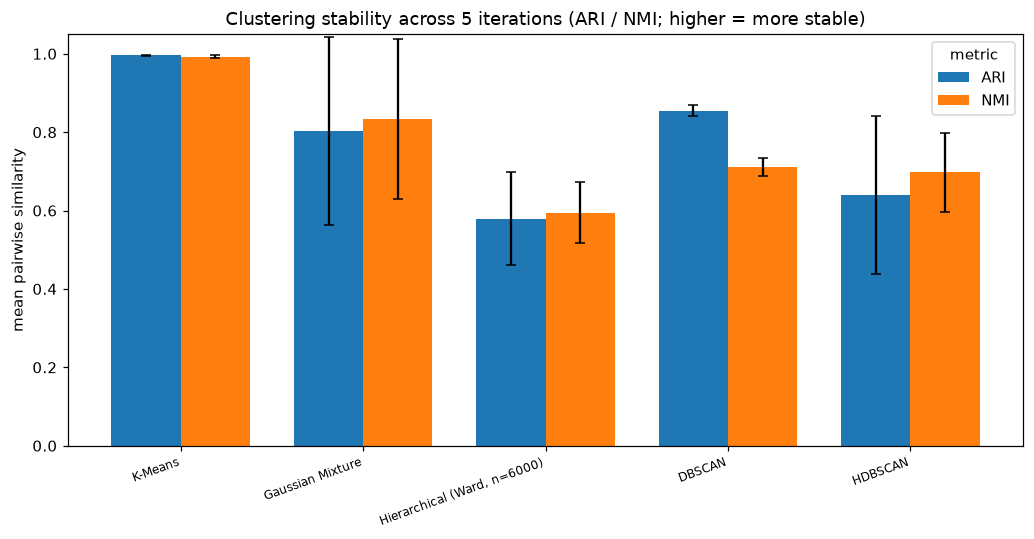

stability: ARI and NMI means stored in ST and stability_metrics.csv


In [8]:
# ================= clustering stability (ARI / NMI across iterations) =================
# Repeat each deployed configuration DRAWS times and measure how similar the resulting
# clusterings are, pairwise, with Adjusted Rand Index (ARI) and Normalized Mutual
# Information (NMI). The only randomised aspect of each configuration is perturbed:
#   - K-Means / GMM ......... random initialisation (different seeds, full data)
#   - Ward-Hierarchical ...... deterministic given data -> 5 subsample draws (n=SS)
#   - DBSCAN ................. deterministic given data -> 5 subsample draws (n=DB_N)
#   - HDBSCAN ................ deterministic given data -> 5 subsample draws (n=30,000)
# Labels are compared on each pair's common players. Higher ARI/NMI = more stable.
from sklearn.metrics.cluster import adjusted_rand_score as _ari
from sklearn.metrics.cluster import normalized_mutual_info_score as _nmi
from itertools import combinations as _comb

DRAWS = 5
S0 = RS + 1000
HDB_N = 30000
ids_all = mat["player_id"].to_numpy()

def _stab_pair(labeled):
    vals = []
    for (i1, l1), (i2, l2) in _comb(labeled, 2):
        ix = np.intersect1d(i1, i2)
        if len(ix) < 100:
            continue
        a = pd.Series(l1, index=i1).reindex(ix).to_numpy(dtype=int)
        b = pd.Series(l2, index=i2).reindex(ix).to_numpy(dtype=int)
        if len(set(a)) < 2 or len(set(b)) < 2:
            continue
        vals.append((_ari(a, b), _nmi(a, b)))
    M = np.asarray(vals)
    return float(M[:, 0].mean()), float(M[:, 0].std()), \
           float(M[:, 1].mean()), float(M[:, 1].std()), int(len(M))

st_rows = []
gmm_k = int(gdf.loc[gdf["silhouette"].idxmax(), "k"])
hier_k = int(hidf.loc[hidf["silhouette"].idxmax(), "k"])
dbe, dbms = float(best["eps"]), int(best["min_samples"])
h_mcs, h_ms = int(hbest["min_cluster_size"]), int(hbest["min_samples"])

labeled = []
for s in range(S0, S0 + DRAWS):
    m = KMeans(n_clusters=6, n_init=10, random_state=s).fit(X)
    labeled.append((ids_all, m.labels_))
st_rows.append(("K-Means", "random init seeds (full data)", *_stab_pair(labeled)))

labeled = []
for s in range(S0, S0 + DRAWS):
    m = GaussianMixture(n_components=gmm_k, covariance_type="full", max_iter=300, random_state=s).fit(X)
    labeled.append((ids_all, m.predict(X)))
st_rows.append(("Gaussian Mixture", "random init seeds (full data)", *_stab_pair(labeled)))

labeled = []
for s in range(S0, S0 + DRAWS):
    rng = np.random.default_rng(s)
    idx = rng.choice(len(X), SS, replace=False)
    h = AgglomerativeClustering(n_clusters=hier_k, linkage="ward").fit(X[idx])
    labeled.append((mat["player_id"].iloc[idx].to_numpy(), h.labels_))
st_rows.append(("Hierarchical (Ward, n=6000)", f"5 subsample draws (n={SS})", *_stab_pair(labeled)))

labeled = []
for s in range(S0, S0 + DRAWS):
    rng = np.random.default_rng(s)
    idx = rng.choice(len(X), DB_N, replace=False)
    db = DBSCAN(eps=dbe, min_samples=dbms).fit(X[idx])
    labeled.append((mat["player_id"].iloc[idx].to_numpy(), db.labels_))
st_rows.append(("DBSCAN", f"5 subsample draws (n={DB_N})", *_stab_pair(labeled)))

labeled = []
for s in range(S0, S0 + DRAWS):
    rng = np.random.default_rng(s)
    idx = rng.choice(len(X), HDB_N, replace=False)
    hd2 = hdbscan.HDBSCAN(min_cluster_size=h_mcs, min_samples=h_ms, core_dist_n_jobs=-1).fit(X[idx])
    labeled.append((mat["player_id"].iloc[idx].to_numpy(), hd2.labels_))
st_rows.append(("HDBSCAN", f"5 subsample draws (n={HDB_N})", *_stab_pair(labeled)))

stma = pd.DataFrame(st_rows, columns=["model", "perturbation", "ari_mean", "ari_std",
                                      "nmi_mean", "nmi_std", "n_pairs"]).round(3)
stma.to_csv(f"{CSV}/stability_metrics.csv", index=False)
display(stma)

fig, ax = plt.subplots(figsize=(9.5, 5))
pos = np.arange(len(stma)); w = 0.38
ax.bar(pos - w / 2, stma["ari_mean"], w, yerr=stma["ari_std"], capsize=3, label="ARI")
ax.bar(pos + w / 2, stma["nmi_mean"], w, yerr=stma["nmi_std"], capsize=3, label="NMI")
ax.set_xticks(pos); ax.set_xticklabels(stma["model"], rotation=20, ha="right", fontsize=8)
ax.set_ylabel("mean pairwise similarity"); ax.set_ylim(0, 1.05)
ax.legend(title="metric")
ax.set_title(f"Clustering stability across {DRAWS} iterations (ARI / NMI; higher = more stable)")
plt.tight_layout()
plt.savefig(f"{VIZ}/stability_comparison.png", dpi=120, bbox_inches="tight")
plt.show(); plt.close(fig)

ST = dict(zip(stma["model"], list(zip(stma["ari_mean"], stma["nmi_mean"]))))
print("stability: ARI and NMI means stored in ST and stability_metrics.csv")


,model,params,n_clusters,n_noise,silhouette,silhouette_core,davies_bouldin,calinski_harabasz,stability_ari,stability_nmi
0,K-Means,k=6.0,6,0,0.234,NaN,1.428,15410.1,0.996,0.993
1,Gaussian Mixture,k=3.0,3,0,0.239,NaN,1.462,17112.3,0.804,0.834
2,"Hierarchical (Ward, n=6000)",k=4.0,4,0,0.228,NaN,1.513,1492.8,0.579,0.595
3,DBSCAN,"eps=1.0, min_samples=20.0",3,2375,0.137,0.303,2.108,362.2,0.855,0.710
4,HDBSCAN,"min_cluster_size=500.0, min_samples=5.0",7,31438,-0.142,0.020,4.062,3486.7,0.640,0.698


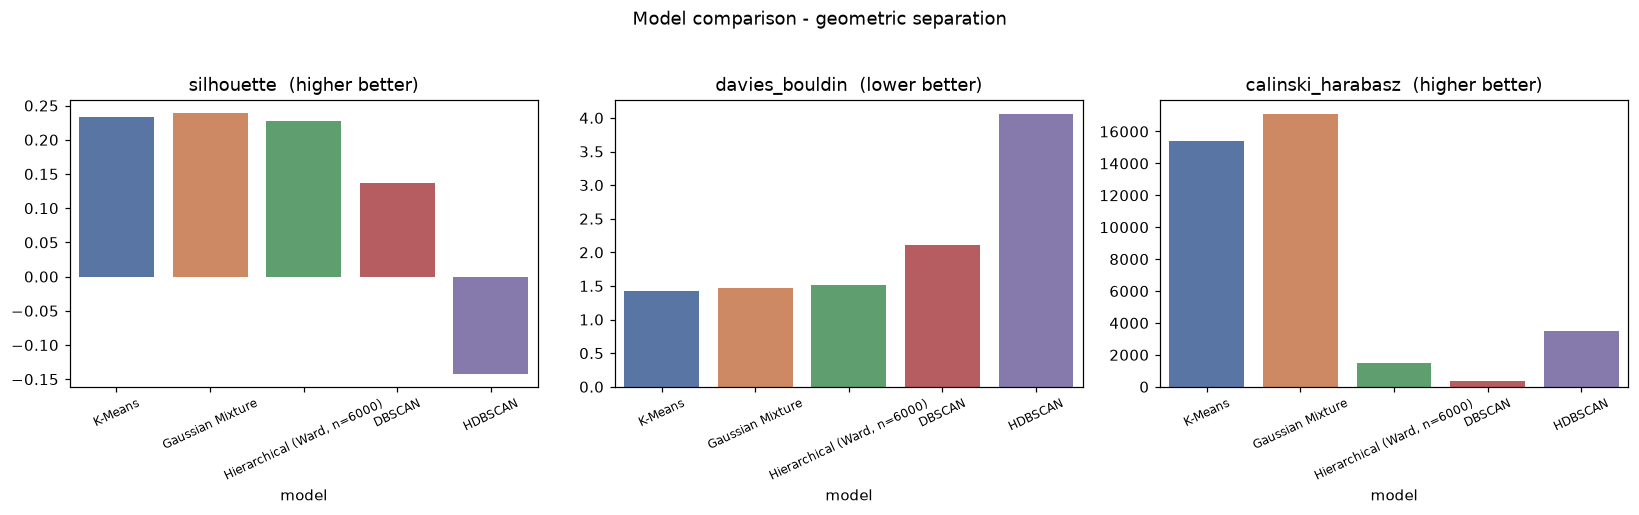


ANSWER: max silhouette 0.239 (Gaussian Mixture) -> poor separation; DB min 1.428, CH max 17112.3.
Best-config silhouette by model: {'K-Means': 0.234, 'Gaussian Mixture': 0.239, 'Hierarchical (Ward, n=6000)': 0.228, 'DBSCAN': 0.137, 'HDBSCAN': -0.142}


In [9]:
def final_row(model, params, df, k=None):
    df2 = df.copy()
    df2["sel"] = df["silhouette_core"] if "silhouette_core" in df.columns else df["silhouette"]
    df2["sel"] = df2["sel"].fillna(-9)
    b = (df2.loc[df2["k"] == k].iloc[0] if k is not None
         else df2.loc[df2["sel"].idxmax()])
    return {"model": model, "params": params.format(**b), "n_clusters": int(b["n_clusters"]),
            "n_noise": int(b["n_noise"]), "silhouette": round(float(b["silhouette"]), 3),
            "silhouette_core": round(float(b.get("silhouette_core", np.nan)), 3),
            "davies_bouldin": round(float(b["davies_bouldin"]), 3),
            "calinski_harabasz": round(float(b["calinski_harabasz"]), 1)}

summ = pd.DataFrame([
    final_row("K-Means", "k={k}", kdf, k=6),
    final_row("Gaussian Mixture", "k={k}", gdf),
    final_row("Hierarchical (Ward, n=6000)", "k={k}", hidf),
    final_row("DBSCAN", "eps={eps}, min_samples={min_samples}", ddf),
    final_row("HDBSCAN", "min_cluster_size={min_cluster_size}, min_samples={min_samples}", hdf),
])
summ = summ.merge(stma[["model", "ari_mean", "nmi_mean"]], on="model", how="left")
summ = summ.rename(columns={"ari_mean": "stability_ari", "nmi_mean": "stability_nmi"})
summ.to_csv(f"{CSV}/clustering_summary.csv", index=False)
display(summ)

lg = pd.DataFrame([
    {"model": r["model"], "metric": "silhouette", "value": r["silhouette"]} for _, r in summ.iterrows()
] + [
    {"model": r["model"], "metric": "davies_bouldin", "value": r["davies_bouldin"]} for _, r in summ.iterrows()
] + [
    {"model": r["model"], "metric": "calinski_harabasz", "value": r["calinski_harabasz"]} for _, r in summ.iterrows()
] + [
    {"model": r["model"], "metric": "stability_ari", "value": r["stability_ari"]} for _, r in summ.iterrows()
] + [
    {"model": r["model"], "metric": "stability_nmi", "value": r["stability_nmi"]} for _, r in summ.iterrows()
])
lg.to_csv(f"{CSV}/metrics_comparison.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
pal = sns.color_palette("deep", len(summ))
for ax, met, inv in zip(axes, ["silhouette", "davies_bouldin", "calinski_harabasz"],
                        [False, True, True]):
    v = lg[lg["metric"] == met].set_index("model")["value"]
    sns.barplot(x=v.index, y=v.values, ax=ax, palette=pal, hue=v.index)
    ax.set_title(met + ("  (lower better)" if inv and met == "davies_bouldin" else "  (higher better)"))
    ax.tick_params(axis="x", rotation=25, labelsize=8)
fig.suptitle("Model comparison - geometric separation", y=1.03)
plt.tight_layout()
plt.savefig(f"{VIZ}/model_comparison.png", dpi=120, bbox_inches="tight")
plt.show(); plt.close(fig)

sil = summ["silhouette"].max(); who = summ.loc[summ["silhouette"].idxmax(), "model"]
verdict = ("strong separation" if sil >= 0.7 else "moderate separation"
           if sil >= 0.5 else "weak separation" if sil >= 0.25 else "poor separation")
print(f"\nANSWER: max silhouette {sil} ({who}) -> {verdict}; "
      f"DB min {summ['davies_bouldin'].min()}, CH max {summ['calinski_harabasz'].max()}.")
print(f"Best-config silhouette by model:", dict(zip(summ['model'], summ['silhouette'])))